# 26 — Phase 7 Result Reconciliation Audit
**Project:** Causal-History Dependence in Robot Policy Recovery  
**Phase:** 8 (History-Intervention Validity and Mechanism Diagnostics)  
**Status:** `Validated Audit`  

### Forensic Objectives:
1. Recompute Phase 7 recovery capability tables from raw rollout records.
2. Verify number of unique physical scenarios ($N=20$) vs. deterministic duplicates ($N=600$).
3. Identify logging defects (hardcoded `detection_rate` and `diagnosis_rate`).
4. Reconcile 5% GRU corrective-action rate with 25% recovery success rate.

In [1]:
import os, sys
cwd = os.getcwd()
if os.path.exists(os.path.join(cwd, "docs")):
    repo_root = cwd
elif os.path.exists(os.path.join(cwd, "..", "docs")):
    repo_root = os.path.abspath(os.path.join(cwd, ".."))
elif os.path.exists(os.path.join(cwd, "causal-history-recovery", "docs")):
    repo_root = os.path.abspath(os.path.join(cwd, "causal-history-recovery"))
else:
    repo_root = os.path.abspath(os.path.join(cwd, ".."))

src_path = os.path.join(repo_root, "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

import json
from collections import defaultdict
import numpy as np

records_path = os.path.join(repo_root, "results", "recovery_capability_validation", "validation_records.jsonl")
with open(records_path) as f:
    records = [json.loads(line) for line in f]

print(f"Total raw rollout records logged: {len(records)}")


Total raw rollout records logged: 600


### 1. Deterministic Rerun Duplication Analysis
Evaluating whether the 3 evaluation seeds (`42, 500, 2000`) produced independent stochastic rollouts or identical deterministic replicates.

In [2]:
by_tuple = defaultdict(list)
for r in records:
    key = (r['policy_id'], r['scenario_uid'], r['condition'])
    by_tuple[key].append(r)

unique_tuples = len(by_tuple)
diff_tuples = 0
for key, group in by_tuple.items():
    r0 = group[0]
    for r in group[1:]:
        if (r['is_success'] != r0['is_success'] or 
            r['corrective_action'] != r0['corrective_action'] or 
            r['recovery_time'] != r0['recovery_time'] or 
            abs(r['control_effort'] - r0['control_effort']) > 1e-9):
            diff_tuples += 1

print(f"Unique (policy, scenario, condition) tuples: {unique_tuples}")
print(f"Records per tuple: {len(list(by_tuple.values())[0])}")
print(f"Tuples with any variation across evaluation seeds: {diff_tuples} / {unique_tuples}")
print(f"Conclusion: Deterministic triplication. True sample size is N = 20 unique physical scenarios.")


Unique (policy, scenario, condition) tuples: 200
Records per tuple: 3
Tuples with any variation across evaluation seeds: 0 / 200
Conclusion: Deterministic triplication. True sample size is N = 20 unique physical scenarios.


### 2. Reconciled Performance Table (True Denominator N = 20)

In [3]:
policies = ['reactive_mlp', 'history_gru', 'recovery_augmented_mlp', 'recovery_augmented_gru', 'privileged_oracle']
conditions = ['B0', 'B4']
scenarios = sorted(list(set(r['scenario_uid'] for r in records)))

print(f"{'Policy':25s} | Cond | Success (k/20) | Succ Rate | Corrective (k/20) | Corr Rate | Mean Effort | RecTime")
print("-" * 110)
for p in policies:
    for c in conditions:
        recs = [by_tuple[(p, s, c)][0] for s in scenarios]
        succ = sum(r['is_success'] for r in recs)
        corr = sum(r['corrective_action'] for r in recs)
        effort = sum(r['control_effort'] for r in recs) / len(recs)
        rectime = sum(r['recovery_time'] for r in recs) / len(recs)
        print(f"{p:25s} | {c:4s} | {succ:2d}/20          | {succ/20*100:5.1f}%    | {corr:2d}/20            | {corr/20*100:5.1f}%     | {effort:11.6f} | {rectime:5.1f}")


Policy                    | Cond | Success (k/20) | Succ Rate | Corrective (k/20) | Corr Rate | Mean Effort | RecTime
--------------------------------------------------------------------------------------------------------------
reactive_mlp              | B0   |  1/20          |   5.0%    |  0/20            |   0.0%     |    0.000012 |  93.3
reactive_mlp              | B4   |  1/20          |   5.0%    |  0/20            |   0.0%     |    0.000012 |  93.3
history_gru               | B0   |  1/20          |   5.0%    |  0/20            |   0.0%     |    0.000012 |  93.3
history_gru               | B4   |  1/20          |   5.0%    |  0/20            |   0.0%     |    0.000012 |  93.3
recovery_augmented_mlp    | B0   |  4/20          |  20.0%    |  8/20            |  40.0%     |    0.000003 |  84.4
recovery_augmented_mlp    | B4   |  4/20          |  20.0%    |  8/20            |  40.0%     |    0.000003 |  84.4
recovery_augmented_gru    | B0   |  5/20          |  25.0%    |  1/20      

### 3. Visual Performance Comparison (Figure 48)

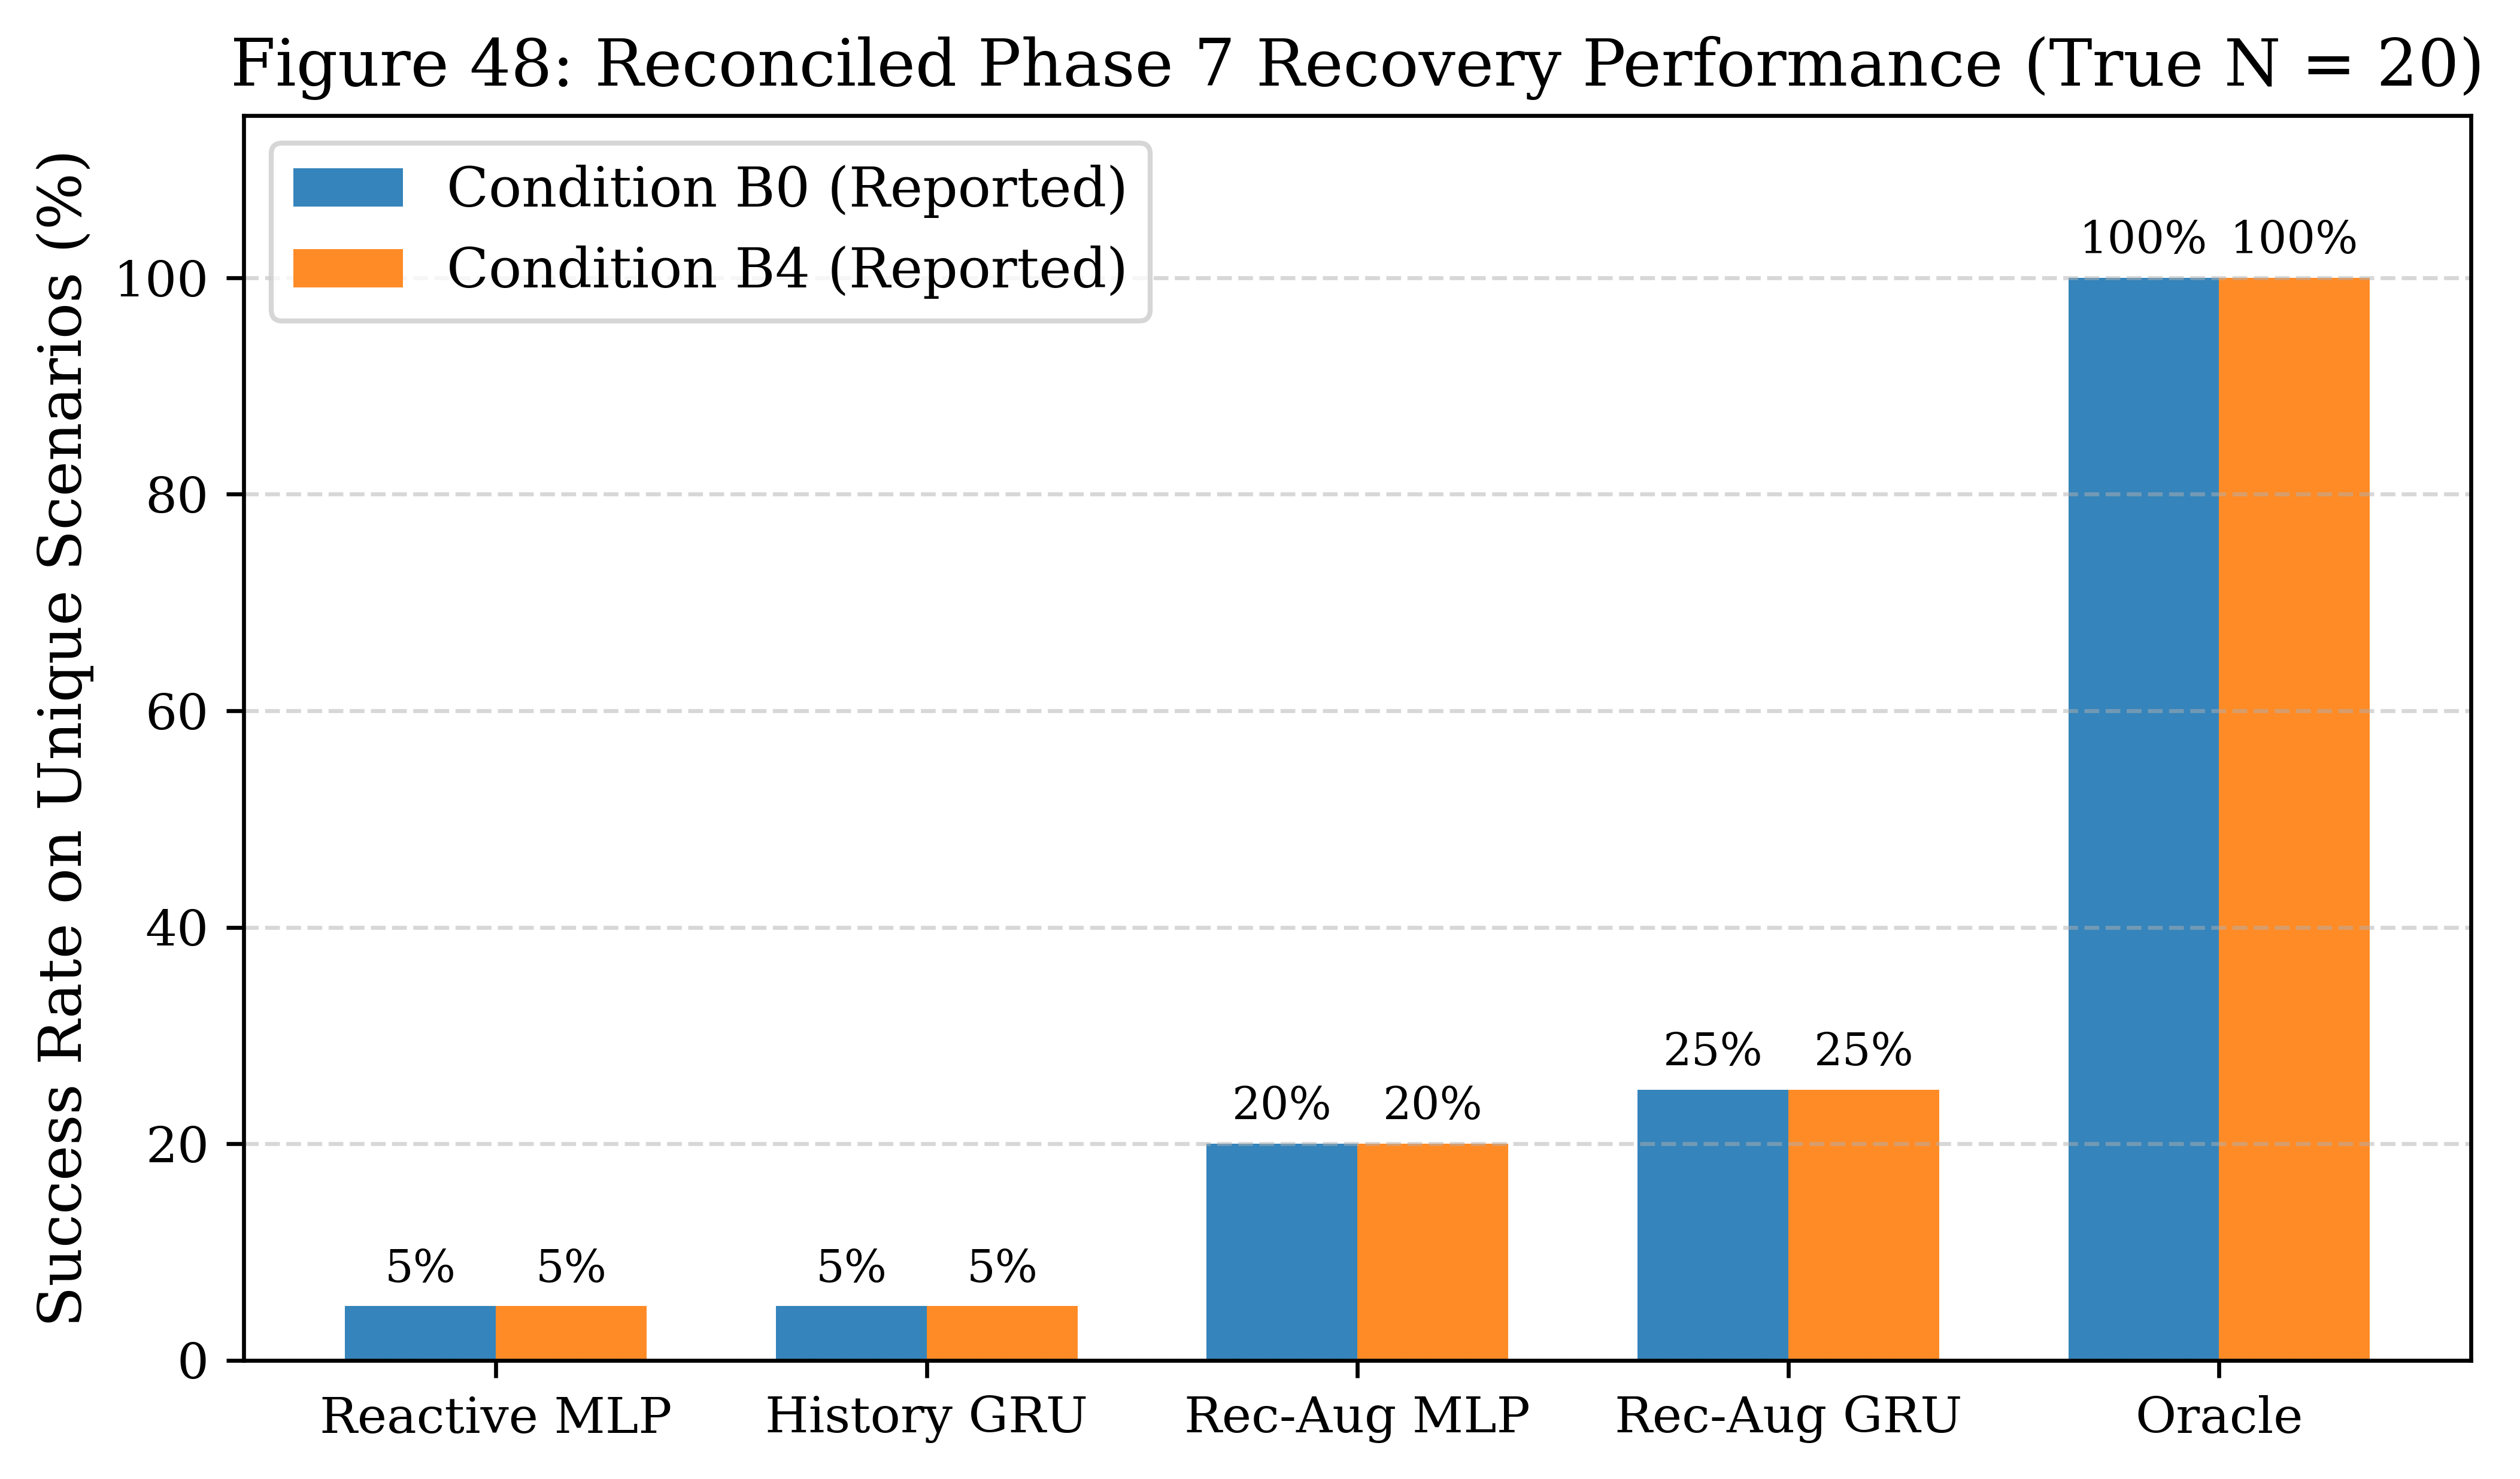

In [4]:
from IPython.display import Image, display
fig_path = os.path.join(repo_root, "figures", "exploratory", "fig48_reconciled_phase_7_performance.png")
if os.path.exists(fig_path):
    display(Image(filename=fig_path))
else:
    print("Figure not found.")
